In [1]:
import polars as pl
from icecream import ic
import seaborn as sns
import matplotlib.pyplot as plt
from utils import gpus_dict

EXPORT_DATA = True

In [2]:
df = pl.read_csv("../data/alibaba-2020/generated/merged_dataframes.csv")
df.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""8fa54171acbc9f16704c03f137ac05…","""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,null,"""MISC""",8,96
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96
"""8a3db37b3795c7c753963d0ef966df…","""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,null,"""MISC""",8,96
"""f114ac24745ec00da7107387afc99e…","""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,null,"""MISC""",8,96


In [3]:
# shift the time data
start = df["start_time"].min()


gpu_max_power_dict: dict[str, float] = {}
gpu_max_power_types: list[str] = []
gpu_max_power_values: list[float] = []
for gpu in gpus_dict:
    gpu_max_power_types.append(gpu)
    gpu_max_power_values.append(gpus_dict[gpu].max_power)

df = df.with_columns(
    pl.col("start_time").mul(1 / 60).floor().alias("start_time_min").cast(pl.Int64),
    pl.col("end_time").mul(1 / 60).floor().alias("end_time_min").cast(pl.Int64),
    pl.col("gpu_type")
    .replace(old=gpu_max_power_types, new=gpu_max_power_values, return_dtype=pl.Float32)
    .alias("gpu_max_power"),
)
df = df.with_columns(pl.col("end_time_min").sub("start_time_min").alias("duration"))
df = df.with_columns(
    pl.col("machine_gpu").mul(1.0 / 100.0).mul("gpu_max_power").alias("power_usage_gpu")
)
df.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu,start_time_min,end_time_min,gpu_max_power,duration,power_usage_gpu
str,str,i64,i64,f64,f64,str,i64,i64,i64,i64,f32,i64,f64
"""8fa54171acbc9f16704c03f137ac05…","""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,null,"""MISC""",8,96,35573,35576,300.0,3,null
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96,46770,46772,300.0,2,577.653265
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96,51401,51406,300.0,5,451.491725
"""8a3db37b3795c7c753963d0ef966df…","""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,null,"""MISC""",8,96,35333,35572,300.0,239,null
"""f114ac24745ec00da7107387afc99e…","""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,null,"""MISC""",8,96,36080,36187,300.0,107,null


In [4]:
df_gpus = df.filter(df["machine_gpu"].is_not_null())
ic(df_gpus["duration"].mean())
ic(df_gpus["machine_gpu"].mean())
ic(len(df_gpus))
df_gpus[["start_time", "machine_gpu"]].sort("start_time").head()
df_gpus['end_time_min'].max() - df_gpus['start_time_min'].min()

ic| df_gpus["duration"].mean(): 108.70891251854572
ic| df_gpus["machine_gpu"].mean(): 135.10286089986613
ic| len(df_gpus): 1767929


73955

In [5]:
def make_ts(
    df: pl.DataFrame,
    start_col="start_time_min",
    end_col="end_time_min",
    value_col="power_usage_gpu",
):
    start_cum = df[[start_col, value_col]].group_by(start_col).sum()
    end_cum = df[[end_col, value_col]].group_by(end_col).sum()
    end_cum = end_cum.with_columns(pl.col(value_col).mul(-1.0).alias(value_col))
    # ic(start_cum)
    # ic(end_cum)

    res_df = start_cum.join(
        end_cum, left_on=start_col, right_on=end_col, how="outer_coalesce"
    )
    res_df = res_df.with_columns(
        pl.col(f"{value_col}_right").fill_null(strategy="zero"),
        pl.col(value_col).fill_null(strategy="zero"),
    )
    res_df = res_df.sort(start_col)
    res_df = res_df.with_columns(
        pl.col(value_col).add(pl.col(f"{value_col}_right")).alias("diff"),
    )

    res_df = res_df.with_columns(
        pl.col("diff").cum_sum().alias("diff_cum"),
    )

    res_df = res_df.rename({start_col: "time"})

    # res_df[value_col].fill_null(0)
    # ic(res_df)

    return res_df

    # for t in start_cum:


ts = make_ts(df_gpus).sort("time")
ts

time,power_usage_gpu,power_usage_gpu_right,diff,diff_cum
i64,f64,f64,f64,f64
33564,1044.318807,0.0,1044.318807,1044.318807
35613,16.162264,0.0,16.162264,1060.481071
35644,166.758705,0.0,166.758705,1227.239776
35659,16.709029,0.0,16.709029,1243.948805
36106,26.399935,0.0,26.399935,1270.34874
…,…,…,…,…
107515,3105.017422,-2893.036115,211.981306,10493.458069
107516,431.204195,-4259.223163,-3828.018968,6665.439101
107517,0.0,-1241.033597,-1241.033597,5424.405504


In [6]:
def reset_start_to_zero(df: pl.DataFrame, cols: list[str]):
    mins_arr = [df[col].min() for col in cols]
    min_start = min(mins_arr)
    return df.with_columns([pl.col(col).sub(min_start) for col in cols])


ts = reset_start_to_zero(ts, ["time"])
ts.head()

time,power_usage_gpu,power_usage_gpu_right,diff,diff_cum
i64,f64,f64,f64,f64
0,1044.318807,0.0,1044.318807,1044.318807
2049,16.162264,0.0,16.162264,1060.481071
2080,166.758705,0.0,166.758705,1227.239776
2095,16.709029,0.0,16.709029,1243.948805
2542,26.399935,0.0,26.399935,1270.34874


Text(0, 0.5, 'Power (watt)')

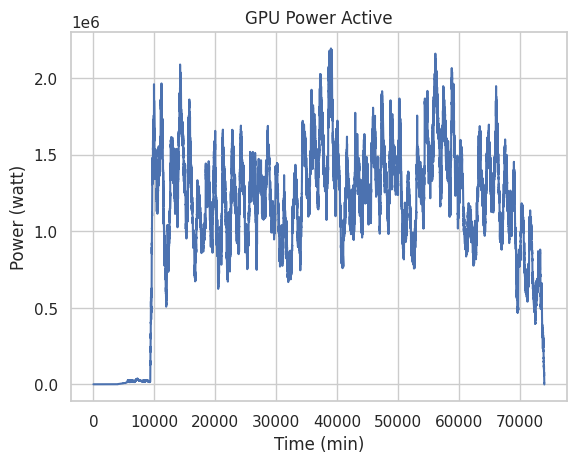

In [8]:
sns.set_theme(style='whitegrid')
sns.lineplot(x=ts["time"], y=ts["diff_cum"])
plt.title("GPU Power Active")
plt.xlabel("Time (min)")
plt.ylabel("Power (watt)")

In [14]:
if EXPORT_DATA:
    ts_csv = ts[["time", "diff_cum"]]
    ts_csv = ts_csv.rename({"diff_cum": "power"})
    ts_csv.write_csv("../data/alibaba-2020/generated/gpu_active_power_min.csv")

In [9]:
def minly_to_hourly(df: pl.DataFrame, time_col: str, hourly_col="time_hourly"):
    df_hourly = df.with_columns(
        [pl.col(time_col).mul(1 / 60).floor().alias(hourly_col)]
    )
    df_hourly = df_hourly.drop(time_col)
    return df_hourly.group_by(hourly_col).mean()


df_hourly = minly_to_hourly(ts, "time").sort("time_hourly")
df_hourly.head()

time_hourly,power_usage_gpu,power_usage_gpu_right,diff,diff_cum
f64,f64,f64,f64,f64
0.0,1044.318807,0.0,1044.318807,1044.318807
34.0,66.543333,0.0,66.543333,1177.223218
42.0,26.399935,0.0,26.399935,1270.34874
53.0,60.819508,0.0,60.819508,1331.168248
57.0,16.600098,0.0,16.600098,1358.807561


<Axes: xlabel='time_hourly', ylabel='diff_cum'>

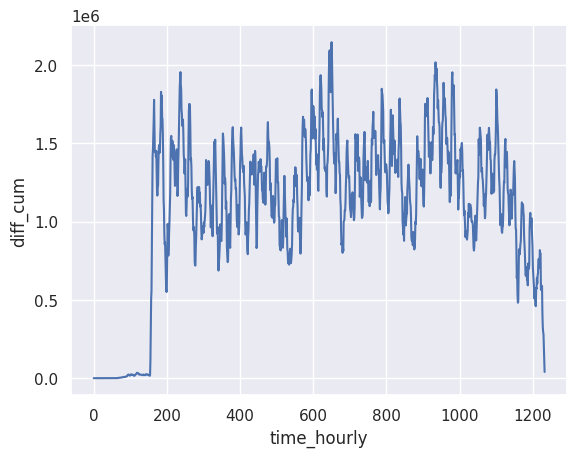

In [10]:
sns.lineplot(df_hourly, x="time_hourly", y="diff_cum")

In [11]:
def minly_to_daily(df: pl.DataFrame, time_col: str, daily_col="time_daily"):
    df_daily = df.with_columns(
        [pl.col(time_col).mul(1 / (60 * 24)).floor().alias(daily_col)]
    )
    df_daily = df_daily.drop(time_col)
    return df_daily.group_by(daily_col).mean()